# Posters data analisis


In [59]:
import numpy as np
import pandas as pd
import requests
from pygments.lexers import go
from PIL import Image
from io import BytesIO
from sklearn.cluster import KMeans
import seaborn as sns
from matplotlib import pyplot as plt
import plotly.express as px

In [60]:
df_posters = pd.read_csv('../data/posters.csv')
df_first_15_movies = pd.read_csv('../data/movies.csv', nrows=15)
df_first_15_movies = df_first_15_movies[['id', 'name']]
df_posters.head()

,id,link
0,1000001,https://a.ltrbxd.com/resized/film-poster/2/7/7...
1,1000002,https://a.ltrbxd.com/resized/film-poster/4/2/6...
2,1000003,https://a.ltrbxd.com/resized/film-poster/4/7/4...
3,1000004,https://a.ltrbxd.com/resized/film-poster/5/1/5...
4,1000005,https://a.ltrbxd.com/resized/film-poster/2/4/0...


Due to the large amount of images we can't show them all, but we can show some examples of the posters.
We will download the first 15 posters and show them.

In [61]:
imgs = []
for i in range(0, 15):
    url = df_posters.iloc[i]['link']
    response = requests.get(url)
    imgs.append(Image.open(BytesIO(response.content)))

## Visualization of the palette
- first we extract the palette of the image using KMeans clustering
- then we show the palette and the mean color of the image
- finally we show the mean color of the image

In [62]:

def preprocess_image(img):
    img = img.resize((150, 150))
    img_array = np.array(img).reshape(-1, 3)
    return img_array


def palette_extraction(img_array):
    kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
    kmeans.fit(img_array)
    return kmeans.cluster_centers_.astype(int)


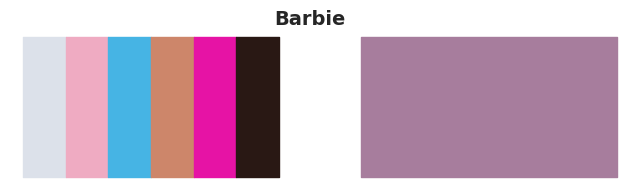

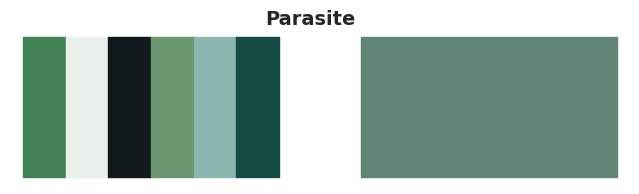

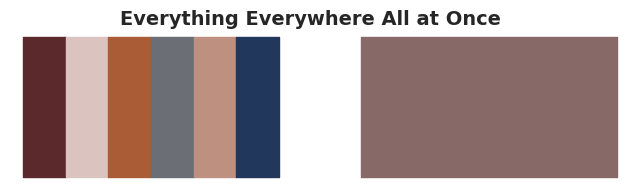

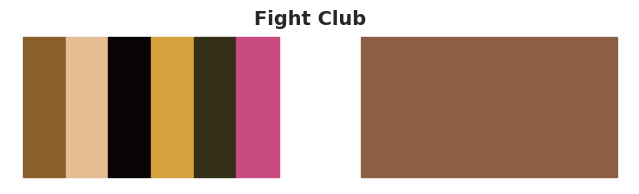

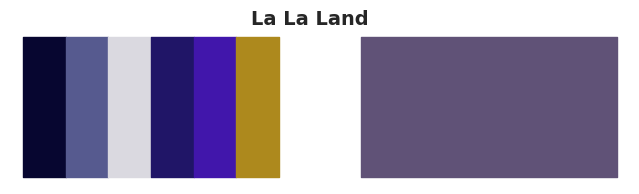

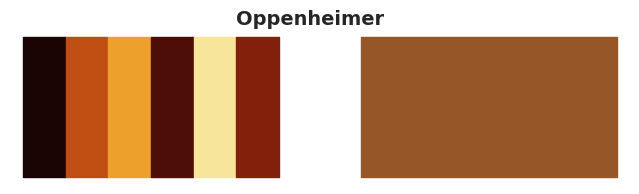

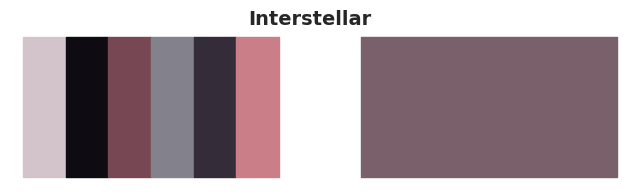

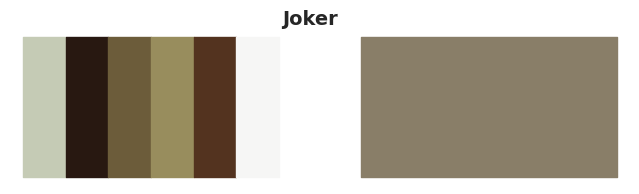

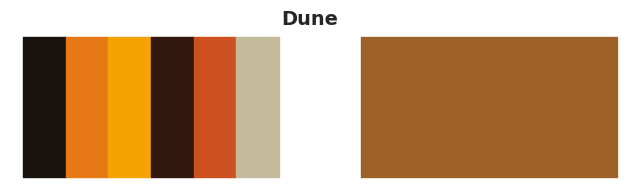

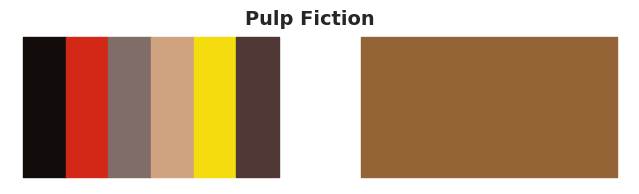

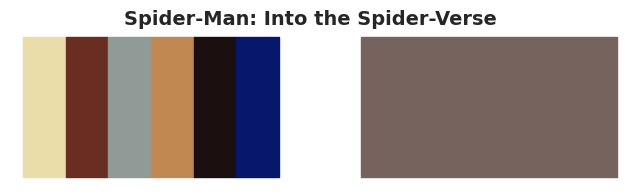

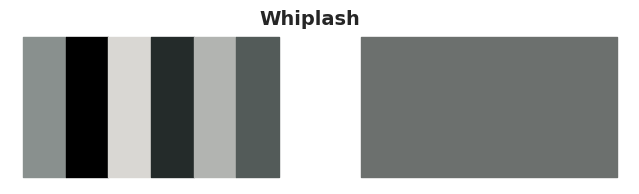

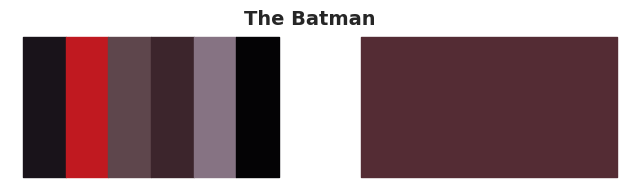

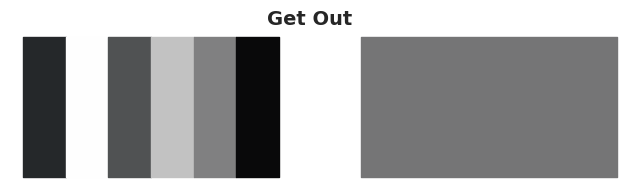

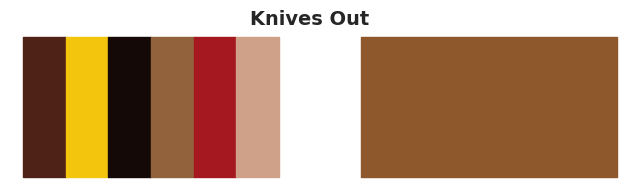

In [63]:
mean_colors = []
for j in range(0, 15):
    fig, ax = plt.subplots(1, 2, figsize=(8, 2))
    ax[0].axis('off')
    ax[1].axis('off')
    img_array = preprocess_image(imgs[j])
    palette = palette_extraction(img_array)
    mean_color = (np.mean(palette, axis=0).astype(int))
    mean_colors.append(mean_color/255)
    #plt.figure(figsize=(8, 2))
    fig.suptitle(df_first_15_movies.iloc[j]['name'], fontsize=14, fontweight="bold")
    for i, colore in enumerate(palette):
        ax[0].fill_between([i, i + 1], 0, 1, color=np.array(colore) / 255)
    ax[1].fill_between([0 , 1], 0, 1, color=np.array(mean_color) / 255)
    plt.xticks([])
    plt.yticks([])
plt.show()


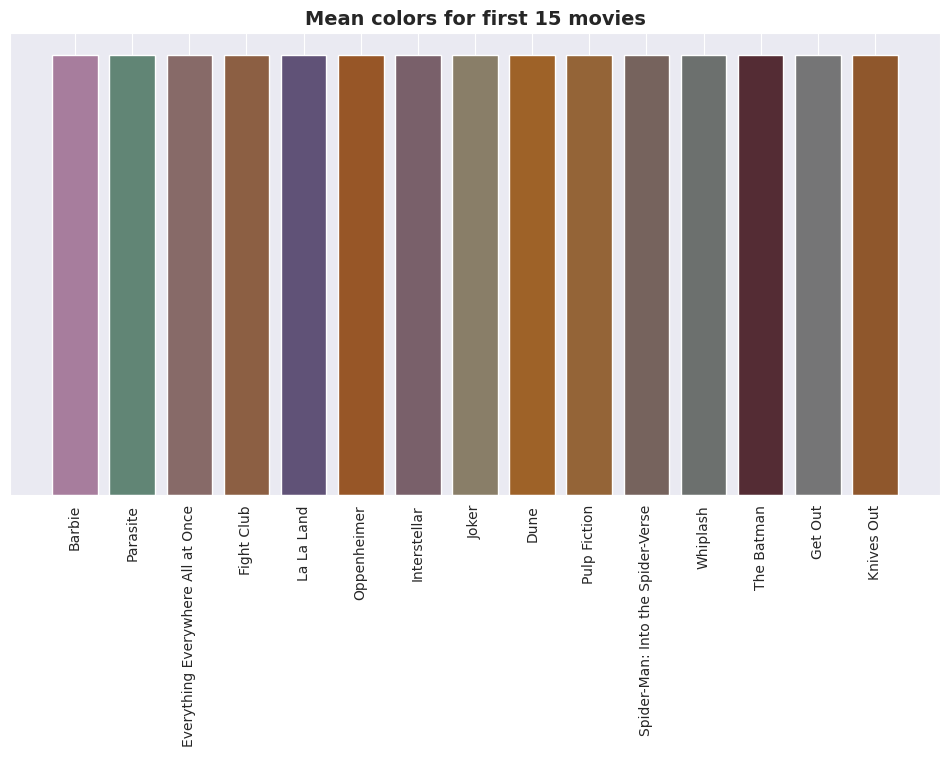

In [64]:
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(df_first_15_movies['name'], [1] * 15, color=mean_colors)  # Usa i colori medi

# Miglioramenti estetici
ax.set_yticks([])
ax.set_xticks(np.arange(0, 15, 1))
ax.set_xticklabels(df_first_15_movies['name'], rotation=90, ha="center", fontsize=10)
ax.set_title("Mean colors for first 15 movies", fontsize=14, fontweight="bold")

plt.show()